# Deep Learning Model Training for Customer Sentiment Analysis


In this walkthrough, you will train and fine-tune a deep learning model to analyze customer feedback and provide actionable insights.

**Scenario:**
Your retail client needs a sentiment analysis model to categorize customer reviews as positive, neutral, or negative and identify trends to enhance their strategy.

**Objective:**
- Preprocess a synthetic dataset of customer reviews for model training.
- Train a sentiment analysis model using an LSTM or fine-tune a pre-trained transformer like BERT.
- Measure accuracy, F1-score, and confusion matrix; identify areas for improvement.
- Deliver a brief summary of key trends, model performance, and recommendations (e.g., addressing delivery complaints).
- Discuss how to explain findings and next steps to a non-technical client.




### Part 1: Load the 'product_reviews.csv' dataset into a pandas Dataframe
**Task 1:**
- Load and Preprocess the dataset.
- Perform EDA to understand patterns in the dataset
- Data Preprocessing
- Split the dataset into training and testing datasets

In [13]:
import pandas as pd
data=pd.read_csv('../data/prod_reviews.csv')
data.head(10)

,Review,Sentiment
0,This product exceeded my expectations! It's hi...,Positive
1,"The product was decent. It worked fine, but it...",Neutral
2,I had a terrible experience with this company....,Negative
3,It's an okay product. Nothing to write home ab...,Neutral
4,Disappointed with the product. It didn't meet ...,Negative
5,Avoid this company at all costs. The service i...,Negative
6,I had a terrible experience with this company....,Negative
7,Avoid this company at all costs. The service i...,Negative
8,This product exceeded my expectations! It's hi...,Positive
9,This product is outstanding! It's exactly what...,Positive


### Exploratory Data Analysis

In [14]:
data.describe()

,Review,Sentiment
count,395,395
unique,140,3
top,This product exceeded my expectations! It's hi...,Positive
freq,22,138


In [15]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Review     395 non-null    str  
 1   Sentiment  395 non-null    str  
dtypes: str(2)
memory usage: 6.3 KB


In [16]:
data["Sentiment"].value_counts()

Sentiment
Positive    138
Negative    129
Neutral     128
Name: count, dtype: int64

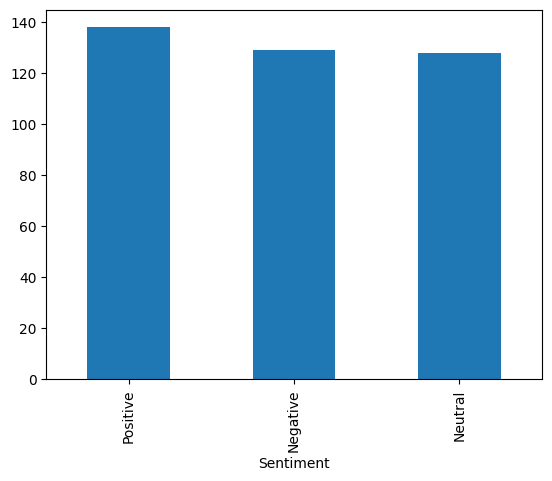

In [17]:
import matplotlib.pyplot as plt 
data["Sentiment"].value_counts().plot(kind='bar')
plt.show()

In [25]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import tensorflow as tf

from sklearn.model_selection import train_test_split
import sklearn

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional

# downloading punkt sentence tokenizer models
nltk.download('punkt')
# downloading stopwords from nltk library
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

# Review text Cleaning
def clean_reviews(text):
    
    # removing html brackets and other square brackets from the string using regex
    regex = re.compile('<.*?>') # r'<.*?>'
    text = re.sub(regex, '', text)

    # removing special characters like @, #, $, etc
    pattern = re.compile(r'[^a-zA-z0-9\s]')
    text = re.sub(pattern,'',text)

    # removing numbers
    pattern = re.compile(r'\d+')
    text = re.sub(pattern,'',text)

    # converting text to lower case
    text = text.lower()
    
    # Tokenization of words
    text = word_tokenize(text)
    
    # Stop words removal
    text = [word for word in text if not word in stop_words]
    
    return text

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\MarcWright\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\MarcWright\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [19]:
# using the clean_reviews function on the dataset
data['Review'] = data['Review'].apply(clean_reviews)

In [20]:
# Step 1: Data Preprocessing
# Extract reviews and sentiments
reviews = data['Review'].values
sentiments = data['Sentiment'].values

# Encode sentiment labels into integers
sentiment_labels = {'Positive': 0, 'Neutral': 1, 'Negative': 2}
sentiments_encoded = [sentiment_labels[sentiment] for sentiment in sentiments]

# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(reviews, sentiments_encoded, test_size=0.2, random_state=42)

# Tokenize the reviews
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(x_train)

x_train_seq = tokenizer.texts_to_sequences(x_train)
x_test_seq = tokenizer.texts_to_sequences(x_test)

# Pad sequences
max_length = 100
x_train_padded = pad_sequences(x_train_seq, maxlen=max_length, padding='post', truncating='post')
x_test_padded = pad_sequences(x_test_seq, maxlen=max_length, padding='post', truncating='post')

# Convert labels to categorical (one-hot encoding)
y_train_categorical = to_categorical(y_train, num_classes=3)
y_test_categorical = to_categorical(y_test, num_classes=3)

### Part 2: Build Model to train a sentiment analysis using an LSTM
**Task:**
- Model Building and Compiling

In [21]:
# Step 2: Build the LSTM Model
model = Sequential(name="LSTM_Sentiment_Analysis")
model.add(Embedding(input_dim=5000, output_dim=128, input_length=max_length))
model.add(Bidirectional(LSTM(128, return_sequences=False)))
model.add(Dropout(0.5))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(3, activation='softmax'))

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Step 3: Train the Model
history = model.fit(x_train_padded, y_train_categorical, epochs=5, batch_size=32, validation_data=(x_test_padded, y_test_categorical))

# Step 4: Evaluate the Model
loss, accuracy = model.evaluate(x_test_padded, y_test_categorical)
loss, accuracy


Epoch 1/5


c:\Users\MarcWright\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 85ms/step - accuracy: 0.3829 - loss: 1.0891 - val_accuracy: 0.5063 - val_loss: 1.0618
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.6234 - loss: 1.0243 - val_accuracy: 0.9747 - val_loss: 0.9030
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.8323 - loss: 0.7663 - val_accuracy: 0.3671 - val_loss: 3.3362
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.7595 - loss: 0.9503 - val_accuracy: 0.9114 - val_loss: 0.4824
Epoch 5/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9241 - loss: 0.3679 - val_accuracy: 0.9241 - val_loss: 0.2568
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9241 - loss: 0.2568


(0.25675421953201294, 0.9240506291389465)

### Part 3: Evaluating Model 

**Task:**
- Evaluating the Model using metrics like precision, recall, and F1-score

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 139ms/step

Classification Report:
              precision    recall  f1-score   support

    Positive       1.00      0.79      0.88        29
     Neutral       0.96      1.00      0.98        24
    Negative       0.84      1.00      0.91        26

    accuracy                           0.92        79
   macro avg       0.93      0.93      0.93        79
weighted avg       0.93      0.92      0.92        79



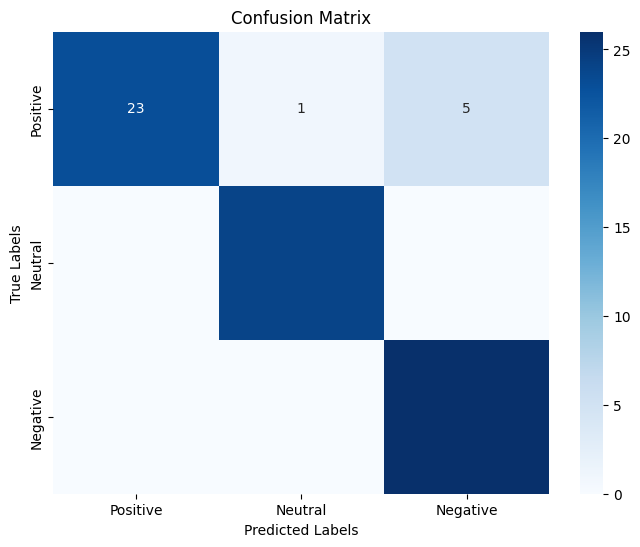

In [22]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Predict on the test set
y_pred = model.predict(x_test_padded)  # Probabilities for each class
y_pred_labels = np.argmax(y_pred, axis=1)  # Convert probabilities to class labels
y_true_labels = np.argmax(y_test_categorical, axis=1)  # True labels from one-hot encoding

# Generate Classification Report
print("\nClassification Report:")
print(classification_report(y_true_labels, y_pred_labels, target_names=list(sentiment_labels.keys())))

# Generate Confusion Matrix
conf_matrix = confusion_matrix(y_true_labels, y_pred_labels)

# Plot Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=list(sentiment_labels.keys()), yticklabels=list(sentiment_labels.keys()))
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix")
plt.show()
